# Resultados del proyecto — Dólar blue (BOB/USD)

Recorrido por los resultados siguiendo las cinco fases del informe. Las tablas
se calculan aquí y se contrastan contra `metricas_reporte.json`; las figuras se
guardan en `outputs/` y son las que usa el informe.


In [1]:
# ── setup: datos y utilidades (el notebook es autocontenido) ───────────────
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import FancyBboxPatch

# rutas: funciona con cwd = modelado/ o cwd = final_project/
MODELADO = (Path.cwd() if (Path.cwd() / "metricas_reporte.json").exists()
            else Path.cwd() / "modelado")
FP, OUT = MODELADO.parent, MODELADO / "outputs"
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(FP))

from charts import figuras  # noqa: E402
from diccionario_datos import (etiqueta, etiqueta_eje,  # noqa: E402
                               etiqueta_tag)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

H = 168                    # ventana de prueba: una semana horaria
HORIZONTES = (1, 24)       # horizontes del objetivo: 1 hora y 1 día
R = json.loads((MODELADO / "metricas_reporte.json").read_text())

panel = pd.read_csv(MODELADO / "panel_diario.csv", parse_dates=["fecha_d"])
mercado = pd.read_csv(
    FP / "data" / "processed" / "market_hourly.csv",
    parse_dates=["fecha"],
).drop(columns=["ret_blue_1h", "fwd_1h", "fwd_6h", "fwd_24h",
                "fwd_72h", "fwd_168h"])
gaceta = pd.read_csv(FP / "data" / "processed" / "gaceta_llm.csv")
gaceta["fecha_publicacion"] = pd.to_datetime(gaceta["fecha_publicacion"],
                                             errors="coerce")

if (MODELADO / "panel_diario.csv").stat().st_mtime > \
        (MODELADO / "metricas_reporte.json").stat().st_mtime:
    print("⚠ panel_diario.csv es más nuevo: volver a correr reporte_modelado.py")

print(f"panel {panel.shape[0]}×{panel.shape[1]} | mercado {len(mercado)} h | "
      f"gaceta {len(gaceta)} normas")


def diagrama(pasos, titulo, figsize=(11.5, 2.3), nota=None):
    """Diagrama de flujo: cajas con flechas, generado en el notebook."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 100); ax.set_ylim(0, 30); ax.axis("off")
    n = len(pasos)
    ancho = 100 / n
    for i, (cab, det) in enumerate(pasos):
        x = i * ancho + ancho / 2
        ax.add_patch(FancyBboxPatch((x - ancho * 0.40, 9), ancho * 0.80, 14,
                                    boxstyle="round,pad=0.6,rounding_size=1.2",
                                    fc="#eef6ff", ec="#0891b2", lw=1.4))
        ax.text(x, 19, cab, ha="center", va="center", fontsize=10,
                fontweight="bold", color="#0f172a")
        ax.text(x, 13.5, det, ha="center", va="center", fontsize=8.2,
                color="#334155")
        if i < n - 1:
            ax.annotate("", xy=(x + ancho * 0.60, 16), xytext=(x + ancho * 0.41, 16),
                        arrowprops=dict(arrowstyle="-|>", color="#0891b2", lw=1.8,
                                        shrinkA=0, shrinkB=0))
    ax.set_title(titulo, fontsize=11.5, pad=6)
    if nota:
        ax.text(50, 3.5, nota, ha="center", fontsize=8, color="#555")
    fig.tight_layout()
    return fig


panel 179×17 | mercado 4318 h | gaceta 169 normas


## 1. Comprensión del negocio

| Objetivo | Pregunta | Métrica |
|:--:|---|---|
| **1** | ¿Se puede pronosticar el nivel del paralelo y la brecha a 1 hora y a 1 día? | RMSE y MAE fuera de muestra vs naïve del mismo horizonte |
| **2** | ¿Las normas de la Gaceta anticipan movimientos de la brecha? | Evento ±5 días y correlación de Spearman |

**Criterios de éxito:** superar al naïve en RMSE y MAE; cobertura del IC95 ≈ 95 %;
efecto de la Gaceta medible, o ausencia documentada.


## 2. Comprensión y obtención de datos

### 2.1 Obtención de datos

Dos fuentes: la API de cotizaciones del blue (resolución horaria) y las normas
de la Gaceta Oficial, extraídas con un LLM.


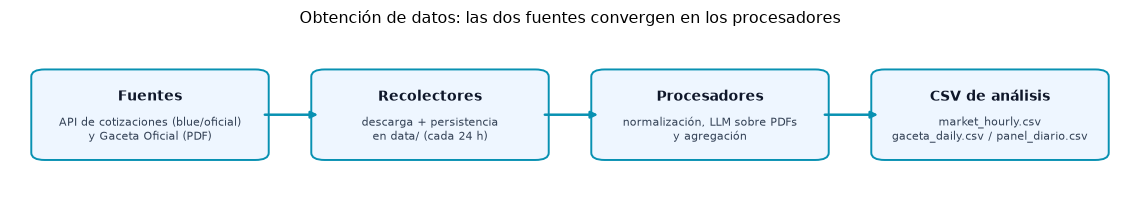

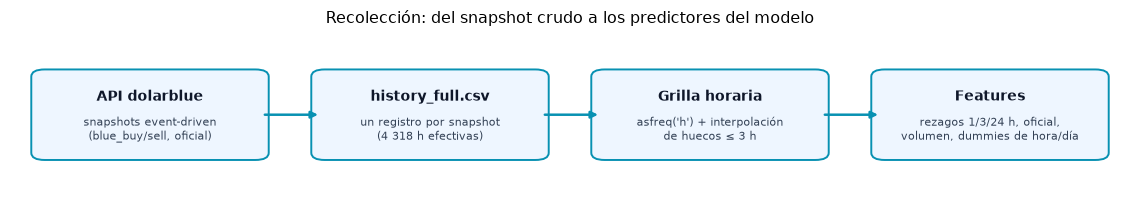

In [2]:
# fig:flujo_datos y fig:recoleccion — diagramas generados aquí
fig = diagrama(
    [("Fuentes", "API de cotizaciones (blue/oficial)\ny Gaceta Oficial (PDF)"),
     ("Recolectores", "descarga + persistencia\nen data/ (cada 24 h)"),
     ("Procesadores", "normalización, LLM sobre PDFs\ny agregación"),
     ("CSV de análisis", "market_hourly.csv\ngaceta_daily.csv / panel_diario.csv")],
    "Obtención de datos: las dos fuentes convergen en los procesadores")
fig.savefig(OUT / "informe_flujo_datos.png", dpi=130, bbox_inches="tight")
plt.show()

fig = diagrama(
    [("API dolarblue", "snapshots event-driven\n(blue_buy/sell, oficial)"),
     ("history_full.csv", "un registro por snapshot\n(4 318 h efectivas)"),
     ("Grilla horaria", "asfreq('h') + interpolación\nde huecos ≤ 3 h"),
     ("Features", "rezagos 1/3/24 h, oficial,\nvolumen, dummies de hora/día")],
    "Recolección: del snapshot crudo a los predictores del modelo")
fig.savefig(OUT / "informe_recoleccion.png", dpi=130, bbox_inches="tight")
plt.show()


### 2.2 Comprensión de los datos (EDA)

Cobertura de cada fuente y las dos señales centrales: nivel blue vs oficial y
brecha cambiaria.


In [3]:
# 2.2 — cobertura y calidad de las fuentes
from models.regresion import grilla_horaria

hor = grilla_horaria(mercado)
display(pd.DataFrame([
    {"Fuente": "Mercado (crudo)", "Filas": len(mercado),
     "Desde": mercado.fecha.min().date(), "Hasta": mercado.fecha.max().date()},
    {"Fuente": "Grilla horaria (EDA)", "Filas": len(hor),
     "Desde": hor.index.min().date(), "Hasta": hor.index.max().date()},
    {"Fuente": "Panel diario (Gaceta)", "Filas": len(panel),
     "Desde": panel.fecha_d.min().date(), "Hasta": panel.fecha_d.max().date()},
    {"Fuente": "Gaceta (LLM)", "Filas": len(gaceta),
     "Desde": gaceta.fecha_publicacion.min().date(),
     "Hasta": gaceta.fecha_publicacion.max().date()},
]))
print(f"intervalo de la serie: {hor.index.to_series().diff().mode().iloc[0]}")
print(f"días del panel con al menos una norma FX: "
      f"{int((panel.n_docs_fx > 0).sum())} de {len(panel)}")

,Fuente,Filas,Desde,Hasta
0,Mercado (crudo),4318,2026-04-27,2026-10-24
1,Grilla horaria (EDA),4321,2026-04-27,2026-10-24
2,Panel diario (Gaceta),179,2026-04-29,2026-10-24
3,Gaceta (LLM),169,2026-06-18,2026-10-20


intervalo de la serie: 0 days 01:00:00
días del panel con al menos una norma FX: 23 de 179


semana del ventana de prueba: 2026-10-17 03:00:00 → 2026-10-24 02:00:00 | 665 snapshots crudos vs 168 filas horarias


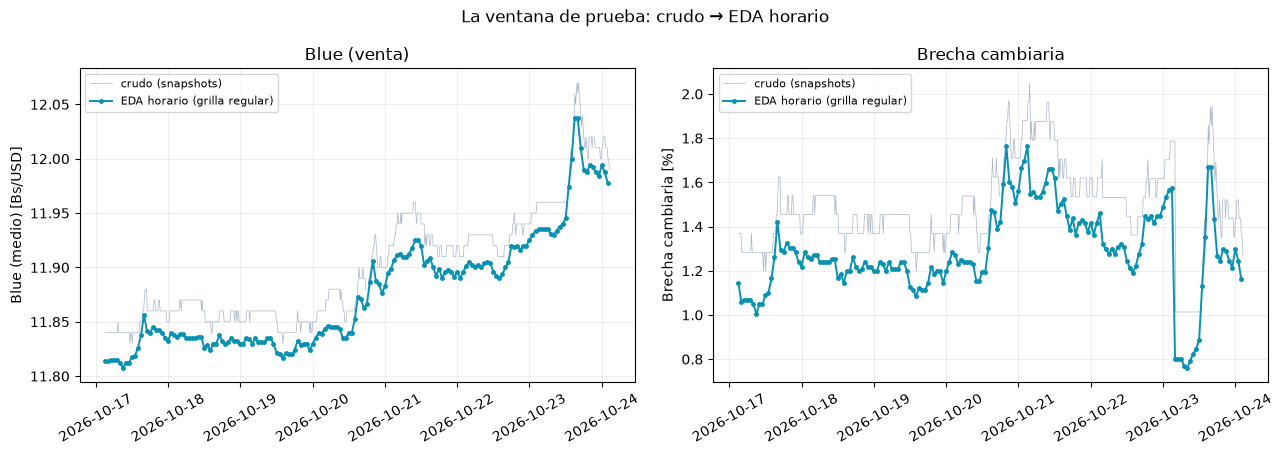

In [4]:
# fig:crudo_vs_eda — snapshots crudos vs serie horaria (semana del ventana de prueba)
raw = pd.read_csv(FP / "data" / "history_full.csv")
raw["fecha"] = pd.to_datetime(raw["timestamp"], unit="s")
raw = raw[(raw["blue_sell"] > 0) & (raw["official_sell"] > 0)].copy()
raw["brecha_snapshot"] = (raw["blue_sell"] / raw["official_sell"] - 1) * 100

h = hor["blue_mid"].dropna()
inicio, fin = h.index[-H], h.index[-1] + pd.Timedelta(hours=1)
crudo = raw.loc[(raw.fecha >= inicio) & (raw.fecha < fin),
                ["fecha", "blue_sell", "brecha_snapshot"]]
eda = hor.loc[inicio:fin - pd.Timedelta(hours=1), ["blue_mid", "brecha_pct"]]
print(f"semana del ventana de prueba: {inicio} → {fin - pd.Timedelta(hours=1)} | "
      f"{len(crudo)} snapshots crudos vs {len(eda)} filas horarias")

fig = figuras.raw_vs_eda(crudo, eda, etiqueta=etiqueta, etiqueta_eje=etiqueta_eje)
fig.savefig(OUT / "informe_crudo_vs_eda.png", dpi=130, bbox_inches="tight")
plt.show()


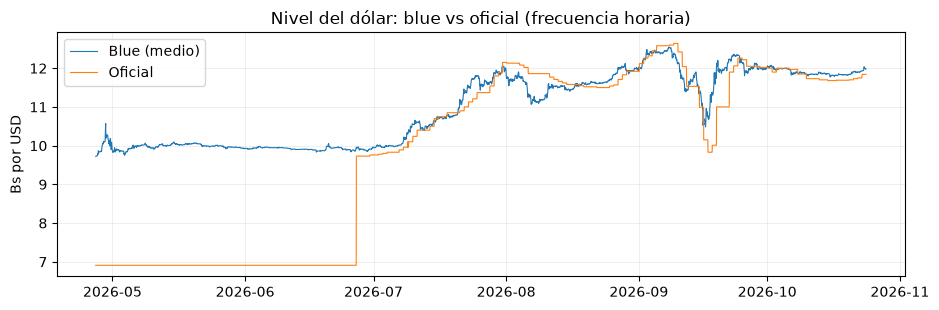

In [5]:
# fig:serie_blue_oficial — nivel del blue vs oficial (serie horaria)
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.plot(hor.index, hor.blue_mid, lw=.8, label="Blue (medio)")
ax.plot(hor.index, hor.oficial_mid, lw=.8, label="Oficial")
ax.set_ylabel("Bs por USD"); ax.legend(); ax.grid(alpha=.25, lw=.6)
ax.set_title("Nivel del dólar: blue vs oficial (frecuencia horaria)")
fig.tight_layout(); plt.show()

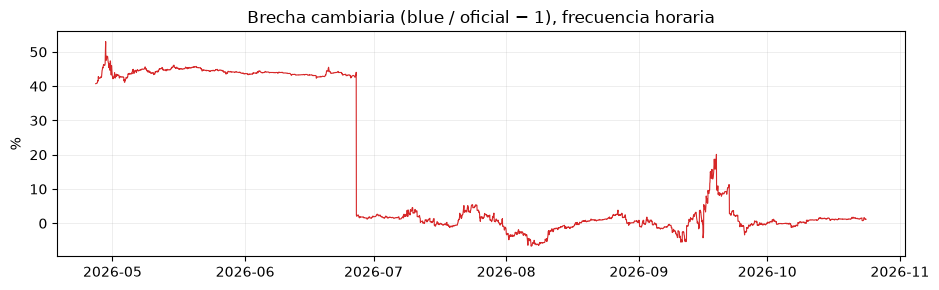

,brecha_pct
count,4321.00
mean,15.40
std,20.68
min,-6.67
25%,0.05
50%,1.68
75%,43.42
max,53.02


In [6]:
# fig:brecha — brecha cambiaria (serie horaria)
fig, ax = plt.subplots(figsize=(9.5, 3.0))
ax.plot(hor.index, hor.brecha_pct, lw=.8, color="tab:red")
ax.set_ylabel("%"); ax.grid(alpha=.25, lw=.6)
ax.set_title("Brecha cambiaria (blue / oficial − 1), frecuencia horaria")
fig.tight_layout(); plt.show()
display(hor.brecha_pct.describe().round(2).to_frame("brecha_pct"))

## 3. Preparación de datos
Cada archivo conserva su resolución y la unión por fecha se hace al modelar.
El panel diario es el producto del cruce mercado × Gaceta.

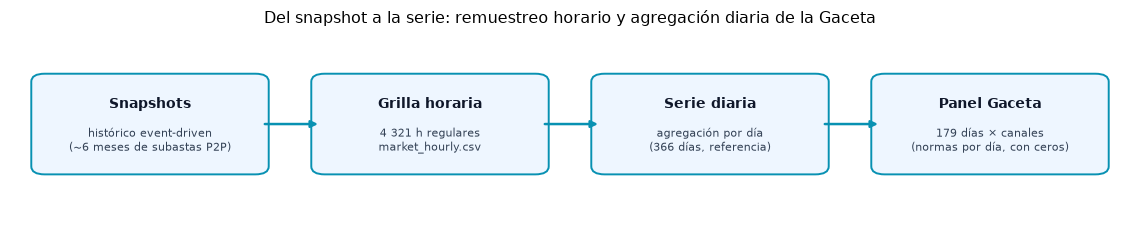

In [7]:
# fig:snapshot — del snapshot a la serie de modelado
fig = diagrama(
    [("Snapshots", "histórico event-driven\n(~6 meses de subastas P2P)"),
     ("Grilla horaria", "4 321 h regulares\nmarket_hourly.csv"),
     ("Serie diaria", "agregación por día\n(366 días, referencia)"),
     ("Panel Gaceta", "179 días × canales\n(normas por día, con ceros)")],
    "Del snapshot a la serie: remuestreo horario y agregación diaria de la Gaceta",
    figsize=(11.5, 2.5))
fig.savefig(OUT / "informe_snapshot.png", dpi=130, bbox_inches="tight")
plt.show()


In [ ]:
# 3 — serie horaria lista para modelar (tab:remuestreo)
print(f"{len(hor)} h | paso {hor.index.to_series().diff().mode().iloc[0]} | "
      f"{hor.index.min()} → {hor.index.max()}")
display(hor[["blue_mid", "oficial_mid", "brecha_pct"]].head(5))

In [9]:
# 3.6 — partición temporal (168 h) y línea base naïve por horizonte
filas = []
for h in HORIZONTES:
    for col in ("blue_mid", "brecha_pct"):
        y = hor[col].dropna()
        tr, te = y.iloc[:-H], y.iloc[-H:]
        nv = y.shift(h).loc[te.index]          # último valor del origen
        filas.append({"serie": etiqueta_eje(col), "horizonte": f"{h} h",
                      "train": len(tr), "test": len(te),
                      "RMSE naïve": round(float(np.sqrt(np.mean((te.values - nv) ** 2))), 4)})
display(pd.DataFrame(filas).set_index(["serie", "horizonte"]).rename_axis(["Nivel", "Horizonte"]))
y = hor["blue_mid"].dropna()
print(f"ventana de prueba: {y.index[-H]} → {y.index[-1]}")
print("El naïve de cada horizonte repite el último valor observado en el origen "
      "(y(t-1) para 1 h, y(t-24) para 24 h).")


,,train,test,RMSE naïve
Nivel,Horizonte,,,
Blue (medio) [Bs/USD],1 h,4153,168,0.0077
Brecha cambiaria [%],1 h,4153,168,0.0910
Blue (medio) [Bs/USD],24 h,4153,168,0.0390
Brecha cambiaria [%],24 h,4153,168,0.2350


ventana de prueba: 2026-10-17 03:00:00 → 2026-10-24 02:00:00
El naïve de cada horizonte repite el último valor observado en el origen (y(t-1) para 1 h, y(t-24) para 24 h).


## 4. Modelado

Tres modelos sobre la serie **horaria**, evaluados en **1 hora y 1 día** en las
últimas 168 h. Cada horizonte tiene una sola línea base —el **naïve del mismo
horizonte**— y la evaluación usa **origen móvil**. Cada bloque muestra
*insumos → entrenamiento → resultados*.


### 4.1 Regresión lineal múltiple

`LinearRegression` sobre **37 predictores** horarios: rezagos de la brecha (1, 3
y 24 h), oficial y volumen rezagados, retorno del blue, los dos canales
cambiarios de la Gaceta y dummies de hora y día de semana.


In [10]:
# 4.1 — INSUMOS: features por horizonte, sin fuga de información
from models.regresion import construir_features_horarias

datos_h, cols_h, train_h, test_h = {}, {}, {}, {}
for h in HORIZONTES:
    datos_h[h], cols_h[h] = construir_features_horarias(mercado, panel, horizonte=h)
    train_h[h], test_h[h] = datos_h[h].iloc[:-H], datos_h[h].iloc[-H:]
    print(f"h={h:2d} h | {len(cols_h[h])} predictores | train {len(train_h[h])} | "
          f"test {len(test_h[h])} | objetivo {test_h[h].fecha.min()} → "
          f"{test_h[h].fecha.max()}")
display(train_h[1][cols_h[1]].head(3))
print("Para h = 24 h el bloque de rezagos se desplaza 23 h más: el predictor más "
      "fresco es el valor observado en t - 24 h.")


h= 1 h | 37 predictores | train 4128 | test 168 | objetivo 2026-10-17 03:00:00 → 2026-10-24 02:00:00
h=24 h | 37 predictores | train 4105 | test 168 | objetivo 2026-10-17 03:00:00 → 2026-10-24 02:00:00


,brecha_lag1h,brecha_lag3h,brecha_lag24h,oficial_lag1h,vol_lag1h,ret_blue_lag1h,n_docs_fx,n_docs_fx_alta,hora_1,hora_2,hora_3,hora_4,hora_5,hora_6,hora_7,hora_8,hora_9,hora_10,hora_11,hora_12,hora_13,hora_14,hora_15,hora_16,hora_17,hora_18,hora_19,hora_20,hora_21,hora_22,hora_23,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6
0,42.4023,42.4023,40.7381,6.91,0.1818,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,42.4023,42.4023,40.7381,6.91,0.1818,0.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,42.3784,42.4023,40.7619,6.91,0.1820,-0.000163,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


Para h = 24 h el bloque de rezagos se desplaza 23 h más: el predictor más fresco es el valor observado en t - 24 h.


In [11]:

# 4.1 — ENTRENAMIENTO: mínimos cuadrados (SVD) por horizonte y target
from sklearn.linear_model import LinearRegression
from models.regresion import ajustar_rl_multiple

pred_rl = {h: {} for h in HORIZONTES}
naive_rl = {h: {} for h in HORIZONTES}
for h in HORIZONTES:
    for target in ("brecha_pct", "blue_mid"):
        pred_rl[h][target], naive_rl[h][target] = ajustar_rl_multiple(
            train_h[h], test_h[h], cols_h[h], target)

m = LinearRegression().fit(train_h[1][cols_h[1]], train_h[1]["brecha_pct"])
coef = pd.Series(m.coef_, index=cols_h[1])
print(f"R² del ajuste (brecha, h=1): "
      f"{m.score(train_h[1][cols_h[1]], train_h[1]['brecha_pct']):.3f}")
display(coef.reindex(coef.abs().sort_values(ascending=False).index)
        .head(5).round(3).to_frame("coeficiente"))


R² del ajuste (brecha, h=1): 0.999


,coeficiente
ret_blue_lag1h,3.769
brecha_lag1h,0.990
hora_2,0.303
hora_3,0.283
hora_16,0.274


,,n,RMSE,MAE,RMSE naïve,RMSE ÷ naïve
Nivel,Horizonte,,,,,
Brecha cambiaria [%],1 h,168,0.1175,0.0730,0.0910,1.29
Blue (medio) [Bs/USD],1 h,168,0.0819,0.0809,0.0077,10.62
Brecha cambiaria [%],24 h,168,0.8863,0.5504,0.2350,3.77
Blue (medio) [Bs/USD],24 h,168,0.1257,0.1191,0.0390,3.22


✔ coincide con metricas_reporte.json
→ la regresión pierde contra el naïve en los dos horizontes.


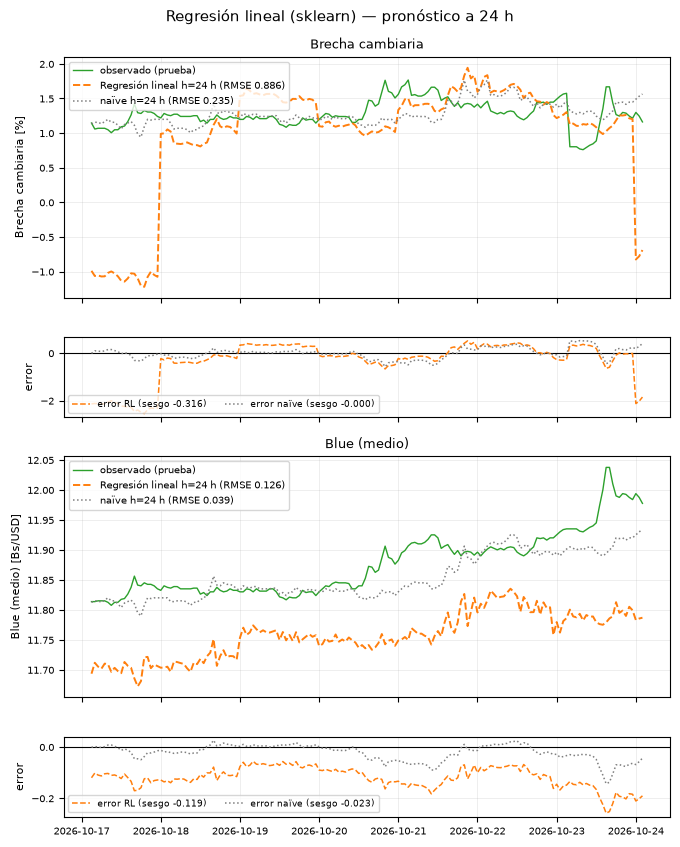

In [12]:
# 4.1 — RESULTADOS por horizonte (tab:rl_multiple)
from metrics import mae, rmse

filas = []
for h in HORIZONTES:
    for target in ("brecha_pct", "blue_mid"):
        y, p, nv = test_h[h][target], pred_rl[h][target], naive_rl[h][target]
        filas.append({"horizonte": f"{h} h", "target": target, "n": len(y),
                      "RMSE": round(rmse(y, p), 4), "MAE": round(mae(y, p), 4),
                      "RMSE naïve": round(rmse(y, nv), 4),
                      "RMSE ÷ naïve": round(rmse(y, p) / rmse(y, nv), 2)})
tabla_rl = pd.DataFrame(filas).set_index(["target", "horizonte"])
display(tabla_rl.rename(index=etiqueta_eje, level=0)
        .rename_axis(["Nivel", "Horizonte"]))

for h in HORIZONTES:
    for target in ("brecha_pct", "blue_mid"):
        assert abs(tabla_rl.loc[(target, f"{h} h"), "RMSE"]
                   - R["por_horizonte"][str(h)]["rl"][target]["rmse"]) < 0.005
print("✔ coincide con metricas_reporte.json")
print("→ la regresión pierde contra el naïve en los dos horizontes.")

# figura: observado vs regresión vs naïve, en el horizonte de un día
h_fig = 24
te_h = test_h[h_fig].set_index("fecha")
fig = figuras.rl_test(te_h, pred_rl[h_fig], naive_rl[h_fig], etiqueta=etiqueta,
                      etiqueta_eje=etiqueta_eje, horizonte=h_fig)
fig.savefig(OUT / "informe_rl_test.png", dpi=130, bbox_inches="tight")
fig.savefig(FP / "report" / "figures" / "fig_rl_test.pdf", bbox_inches="tight")
plt.show()


### 4.2 OLS con errores HAC

Mismo diseño, con errores **Newey–West de 24 rezagos** (un ciclo diario). Los β
no cambian; cambia el error estándar.


In [13]:
# 4.2 — INSUMOS: mismo diseño contemporáneo (h = 1 h), sin fuga de información
train_1, cols_1 = train_h[1], cols_h[1]
print(f"predictores: {len(cols_1)} | observaciones: {len(train_1)}")
display(train_1[["brecha_pct"] + cols_1[:6]].head(5))


predictores: 37 | observaciones: 4128


,brecha_pct,brecha_lag1h,brecha_lag3h,brecha_lag24h,oficial_lag1h,vol_lag1h,ret_blue_lag1h
0,42.4023,42.4023,42.4023,40.7381,6.91,0.1818,0.000000
1,42.3784,42.4023,42.4023,40.7381,6.91,0.1818,0.000000
2,42.4385,42.3784,42.4023,40.7619,6.91,0.1820,-0.000163
3,42.5470,42.4385,42.4023,40.8104,6.91,0.1819,0.000417
4,42.6194,42.5470,42.3784,40.8589,6.91,0.1819,0.000762


In [14]:
# 4.2 — ENTRENAMIENTO: OLS + HAC (24 rezagos)
from models.regresion import ajustar_ols_hac

fit_hac, cols_ok = ajustar_ols_hac(train_1, cols_1, "brecha_pct", maxlags=24)
print(f"R² {fit_hac.rsquared:.4f} | n = {int(fit_hac.nobs)} | "
      f"predictores usados {len(cols_ok)} de {len(cols_1)}")


R² 0.9987 | n = 4128 | predictores usados 37 de 37


,β,ee HAC,p,"IC 2,5","IC 97,5"
brecha_lag1h,0.9899,0.0064,0.0000,0.9773,1.0024
oficial_lag1h,-0.0263,0.0098,0.0075,-0.0456,-0.0070


✔ coincide con el informe


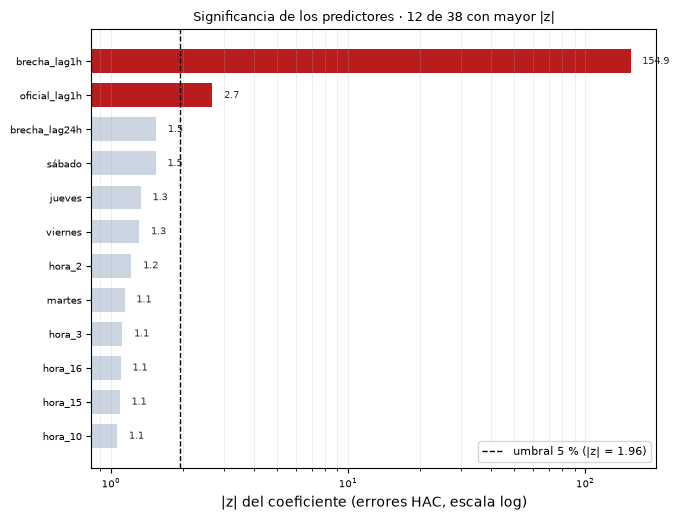

In [15]:
# 4.2 — RESULTADOS: coeficientes significativos al 5 % (tab:ols_hac)
t = fit_hac.summary2().tables[1].rename(columns={
    "Coef.": "β", "Std.Err.": "ee HAC", "P>|z|": "p",
    "[0.025": "IC 2,5", "0.975]": "IC 97,5"})
sig = t[t["p"] < 0.05].sort_values("p")[["β", "ee HAC", "p", "IC 2,5", "IC 97,5"]]
display(sig.round(4))

assert abs(sig.loc["brecha_lag1h", "β"] - 0.9899) < 0.01
print("✔ coincide con el informe")

# figura: |z| de cada predictor frente al umbral del 5 %
completos = t.copy()
completos["z"] = completos["β"] / completos["ee HAC"]
fig = figuras.z_hac(completos, umbral=1.96, etiqueta=etiqueta)
fig.savefig(OUT / "informe_hac_z.png", dpi=130, bbox_inches="tight")
fig.savefig(FP / "report" / "figures" / "fig_hac_z.pdf", bbox_inches="tight")
plt.show()

### 4.3 ARIMA

Serie univariada con **90 días (2 160 h)** de entrenamiento. El orden sale de un
grid por AIC con $p,q \leq 2$. La búsqueda **se repite en cada horizonte**,
porque la ventana se desplaza con él. Evaluación con origen móvil y banda IC95.


In [16]:
# 4.3 — INSUMOS: ventana de entrenamiento y raíz unitaria por horizonte
import warnings
warnings.filterwarnings("ignore")
from models.arima import adf_pvalores

VENTANA_H = 90 * 24
series = {c: hor[c].dropna() for c in ("blue_mid", "brecha_pct")}
split = {c: y.index[-(H + 1)] for c, y in series.items()}

for nombre, y in series.items():
    for h in HORIZONTES:
        origen0 = y.index[y.index > split[nombre]][0] - pd.Timedelta(hours=h)
        tr = y.loc[:origen0].iloc[-VENTANA_H:]
        p_nivel, p_diff = adf_pvalores(tr)
        print(f"{nombre:11s} h={h:2d} h | origen inicial {origen0:%Y-%m-%d %H:%M} | "
              f"n_train={len(tr)} | ADF nivel p={p_nivel:.4f} | diff(1) p={p_diff:.4f}")
print("La ventana de entrenamiento se desplaza con el horizonte: el ARIMA a un día "
      "solo puede usar datos hasta 24 h antes del primer objetivo.")


blue_mid    h= 1 h | origen inicial 2026-10-17 02:00 | n_train=2160 | ADF nivel p=0.0008 | diff(1) p=0.0000
blue_mid    h=24 h | origen inicial 2026-10-16 03:00 | n_train=2160 | ADF nivel p=0.0013 | diff(1) p=0.0000
brecha_pct  h= 1 h | origen inicial 2026-10-17 02:00 | n_train=2160 | ADF nivel p=0.0306 | diff(1) p=0.0000
brecha_pct  h=24 h | origen inicial 2026-10-16 03:00 | n_train=2160 | ADF nivel p=0.0301 | diff(1) p=0.0000
La ventana de entrenamiento se desplaza con el horizonte: el ARIMA a un día solo puede usar datos hasta 24 h antes del primer objetivo.


In [17]:
# 4.3 — ENTRENAMIENTO: grid search (p,d,q) × tendencia por AIC, en cada horizonte
from models.arima import seleccionar_por_horizonte

elegidos = {}
for nombre, y in series.items():
    elegidos[nombre] = {}
    for h in HORIZONTES:
        sel = seleccionar_por_horizonte(y, split[nombre], h,
                                        ventana_h=VENTANA_H, max_pq=2)
        elegidos[nombre][h] = sel
        print(f"{nombre:11s} h={h:2d} h → {sel['modelo']} trend={sel['trend']!r} | "
              f"AIC={sel['aic']:9.1f} | n_train={sel['n_train']}")
print("El orden elegido coincide en ambos horizontes, pero el AIC se calcula sobre "
      "ventanas desplazadas: el modelo a un día no ve las últimas 23 h.")


blue_mid    h= 1 h → ARIMA(2,1,1) trend='n' | AIC=  -9305.0 | n_train=2160


blue_mid    h=24 h → ARIMA(2,1,1) trend='n' | AIC=  -9301.2 | n_train=2160


brecha_pct  h= 1 h → ARIMA(2,1,2) trend='n' | AIC=   2926.5 | n_train=2160


brecha_pct  h=24 h → ARIMA(2,1,2) trend='n' | AIC=   2931.4 | n_train=2160
El orden elegido coincide en ambos horizontes, pero el AIC se calcula sobre ventanas desplazadas: el modelo a un día no ve las últimas 23 h.


,,AIC,n,RMSE,MAE,RMSE naïve,RMSE ÷ naïve,cobertura IC95
Modelo,Horizonte,,,,,,,
"ARIMA(2,1,1)",1 h,-9305.0,168,0.0074,0.0050,0.0077,0.96,1.0
"ARIMA(2,1,2)",1 h,2926.5,168,0.0907,0.0492,0.0910,1.00,1.0
"ARIMA(2,1,1)",24 h,-9301.2,168,0.0390,0.0277,0.0390,1.00,1.0
"ARIMA(2,1,2)",24 h,2931.4,168,0.2338,0.1786,0.2350,0.99,1.0


✔ coincide con metricas_reporte.json
→ el ARIMA empata con el naïve: a 1 h lo iguala o mejora por poco; a 24 h la diferencia es indistinguible.


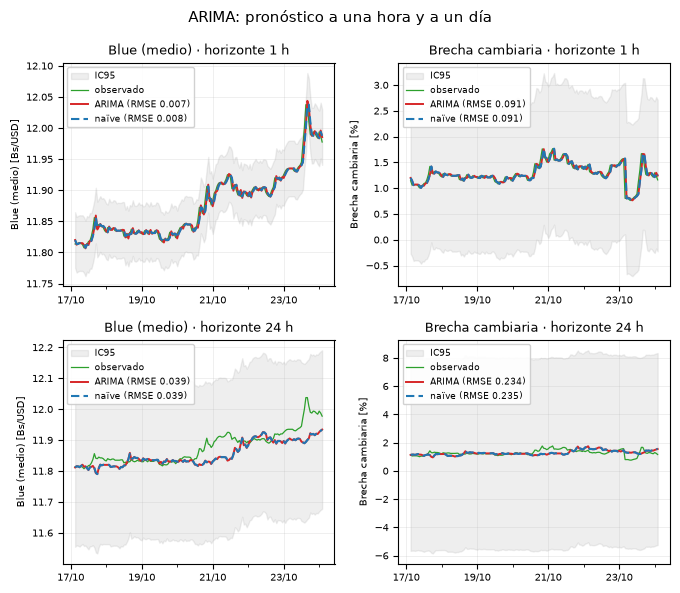

In [18]:
# 4.3 — RESULTADOS walk-forward por horizonte (tab:arima)
from models.arima import arima_holdout_detalle, arima_walkforward

res_ar = {}
for nombre, y in series.items():
    ventana = y.iloc[-(VENTANA_H + H):]
    res_ar[nombre] = arima_holdout_detalle(ventana, n_test=H)

pred_ar = {h: {} for h in HORIZONTES}
naive_ar = {h: {} for h in HORIZONTES}
banda_ar = {h: {} for h in HORIZONTES}
filas_ar = []
for h in HORIZONTES:
    for nombre, y in series.items():
        sel = elegidos[nombre][h]          # orden elegido para ESTE horizonte
        pred_ar[h][nombre], naive_ar[h][nombre], lo, hi = arima_walkforward(
            y, split[nombre], h, sel["order"], trend=sel["trend"])
        banda_ar[h][nombre] = pd.DataFrame({"lo": lo, "hi": hi})
        real = y.loc[pred_ar[h][nombre].index]
        e, en = real - pred_ar[h][nombre], real - naive_ar[h][nombre]
        filas_ar.append({
            "horizonte": f"{h} h", "modelo": sel["modelo"],
            "AIC": sel["aic"], "n_train": sel["n_train"], "n": len(real),
            "RMSE": round(float(np.sqrt((e ** 2).mean())), 4),
            "MAE": round(float(e.abs().mean()), 4),
            "RMSE naïve": round(float(np.sqrt((en ** 2).mean())), 4),
            "RMSE ÷ naïve": round(float(np.sqrt((e ** 2).mean())
                                        / np.sqrt((en ** 2).mean())), 2),
            "cobertura IC95": round(float(((real >= lo) & (real <= hi)).mean()), 3),
        })
tabla_ar = pd.DataFrame(filas_ar).set_index(["modelo", "horizonte"])
display(tabla_ar.rename_axis(["Modelo", "Horizonte"]).drop(columns="n_train"))

for h in HORIZONTES:
    for nombre in series:
        assert abs(tabla_ar.loc[(elegidos[nombre][h]["modelo"], f"{h} h"), "RMSE"]
                   - R["por_horizonte"][str(h)]["arima"][nombre]["rmse"]) < 0.005
print("✔ coincide con metricas_reporte.json")
print("→ el ARIMA empata con el naïve: a 1 h lo iguala o mejora por poco; a 24 h "
      "la diferencia es indistinguible.")

# figura: el ARIMA en los dos horizontes (una fila por horizonte)
datos_fig = {h: {t: (pred_ar[h][t],
                    series[t].loc[pred_ar[h][t].index],
                    naive_ar[h][t],
                    banda_ar[h][t]) for t in series}
             for h in HORIZONTES}
fig = figuras.arima_horizontes(datos_fig, etiqueta=etiqueta,
                               etiqueta_eje=etiqueta_eje, horizontes=HORIZONTES)
fig.savefig(OUT / "informe_arima_test.png", dpi=130, bbox_inches="tight")
fig.savefig(FP / "report" / "figures" / "fig_arima_test.pdf", bbox_inches="tight")
plt.show()


In [19]:
# 4.3 — RESULTADOS: criterios de información y parámetros
# (tab:criterios_info y tab:arima_params)
crit = pd.DataFrame({k: v["criterios"] for k, v in res_ar.items()}).T
crit[["k", "n"]] = crit[["k", "n"]].astype(int)
crit.index = [etiqueta_eje(k) for k in crit.index]
display(crit)

for nombre, v in res_ar.items():
    print(f"{etiqueta_eje(nombre)} — {v['modelo']}")
    display(pd.DataFrame(v["parametros"]).set_index("parametro").round(4))


,k,n,logL,AIC,BIC,AICc,HQIC
Blue (medio) [Bs/USD],4,2160,4656.5,-9305.0,-9282.3,-9305.0,-9296.7
Brecha cambiaria [%],5,2160,-1458.3,2926.5,2954.9,2926.6,2936.9


Blue (medio) [Bs/USD] — ARIMA(2,1,1)


,coef,ee,z,p,ic_inf,ic_sup
parametro,,,,,,
ar.L1,-0.3504,0.1236,-2.83,0.0046,-0.5926,-0.1081
ar.L2,0.0431,0.0292,1.48,0.1393,-0.0140,0.1003
ma.L1,0.5579,0.1226,4.55,0.0000,0.3175,0.7983
sigma2,0.0008,0.0000,125.39,0.0000,0.0008,0.0008


Brecha cambiaria [%] — ARIMA(2,1,2)


,coef,ee,z,p,ic_inf,ic_sup
parametro,,,,,,
ar.L1,0.0677,0.0965,0.70,0.4831,-0.1215,0.2568
ar.L2,0.6443,0.0728,8.85,0.0000,0.5016,0.7870
ma.L1,-0.0446,0.0876,-0.51,0.6110,-0.2163,0.1271
ma.L2,-0.7310,0.0641,-11.40,0.0000,-0.8567,-0.6053
sigma2,0.2260,0.0012,189.60,0.0000,0.2237,0.2284


### 4.4 Comparativa del Objetivo 1

Cada modelo frente al naïve de **su mismo horizonte**, en RMSE y MAE. Un cociente
menor que 1 es mejor que la línea base; mayor que 1, peor.


In [20]:
# tab:comparativa — cada modelo contra el naïve de su horizonte (RMSE y MAE)
filas = []
for h in HORIZONTES:
    ph = R["por_horizonte"][str(h)]
    for target in ("brecha_pct", "blue_mid"):
        for clave, nombre in (("arima", ph["arima"][target]["modelo"]),
                              ("rl", "RL múltiple")):
            v = ph[clave][target]
            filas.append({"Target": target, "Horizonte": f"{h} h",
                          "Modelo": nombre,
                          "RMSE": v["rmse"], "RMSE ÷ naïve": v["ratio"],
                          "MAE": v["mae"],
                          "MAE ÷ naïve": round(v["mae"] / v["mae_naive"], 2)})
comp = pd.DataFrame(filas).set_index(["Target", "Horizonte", "Modelo"])
display(comp.rename(index=etiqueta_eje, level=0)
        .rename_axis(["Nivel", "Horizonte", "Modelo"]))
print("÷ naïve = 1 es empate; > 1 es peor. El MAE es la magnitud del costo "
      "de operación de la sección 5.")


RMSE  RMSE ÷ naïve     MAE  MAE ÷ naïve
Nivel                 Horizonte Modelo                                                 
Brecha cambiaria [%]  1 h       ARIMA(2,1,2)  0.0907         0.996  0.0492         1.00
                                RL múltiple   0.1175         1.290  0.0730         1.48
Blue (medio) [Bs/USD] 1 h       ARIMA(2,1,1)  0.0074         0.955  0.0050         1.00
                                RL múltiple   0.0819        10.621  0.0809        16.18
Brecha cambiaria [%]  24 h      ARIMA(2,1,2)  0.2338         0.995  0.1786         0.99
                                RL múltiple   0.8863         3.772  0.5504         3.05
Blue (medio) [Bs/USD] 24 h      ARIMA(2,1,1)  0.0390         0.999  0.0277         1.00
                                RL múltiple   0.1257         3.220  0.1191         4.30

÷ naïve = 1 es empate; > 1 es peor. El MAE es la magnitud del costo de operación de la sección 5.



### 4.5 Objetivo 2 — Gaceta ↔ brecha

Evento de ±5 días por tag y correlación de Spearman contra el retorno del blue.


,media 5 h,media 1 d,media 3 d,media 5 d
comercio_exterior,-0.053,0.343,0.508,1.326
contrataciones_estado,0.115,0.292,0.042,0.136
credito_financiero,0.192,0.664,1.060,1.322
deuda_externa,-0.204,0.053,0.188,0.870
divisas_control_cambios,-0.285,-0.311,0.054,0.953
fiscal_presupuesto,0.497,1.061,3.830,3.378
general_administrativo,0.015,0.255,1.031,1.210
impuestos,0.178,0.374,0.575,1.051
mineria_energia,0.169,0.340,0.026,0.206


,n 5 h,n 1 d,n 3 d,n 5 d
comercio_exterior,12,12,12,12
contrataciones_estado,1,1,1,1
credito_financiero,7,7,7,7
deuda_externa,6,6,6,6
divisas_control_cambios,5,5,5,5
fiscal_presupuesto,4,4,4,4
general_administrativo,42,42,42,42
impuestos,22,22,22,22
mineria_energia,18,18,18,18


,n días,ρ (t),ρ (t+1)
comercio_exterior,24.0,0.023,0.014
contrataciones_estado,2.0,-0.059,0.020
credito_financiero,15.0,0.031,-0.017
deuda_externa,15.0,-0.018,-0.094
divisas_control_cambios,9.0,-0.026,-0.099
fiscal_presupuesto,10.0,0.019,0.083
general_administrativo,88.0,0.034,0.008
impuestos,41.0,0.039,0.095
mineria_energia,34.0,0.160,0.036


pares fecha–tag: 249 totales, 117 con datos de mercado (2026-04-27 → 2026-10-24)


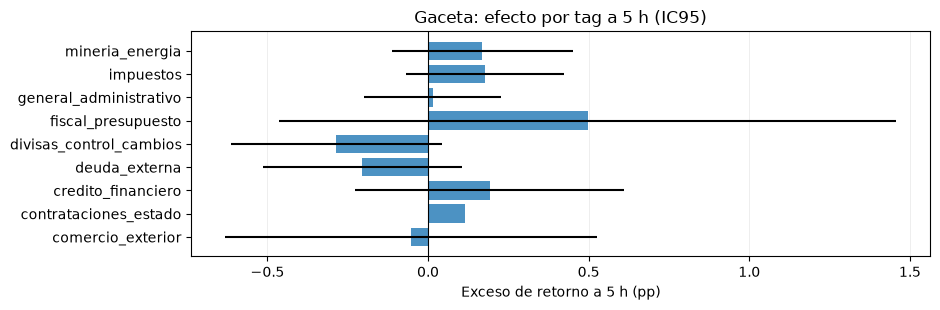

In [21]:
# tab:eventos y tab:spearman — Gaceta ↔ brecha
HOR = ["5 h", "1 d", "3 d", "5 d"]
ev = pd.DataFrame({t: {h: d[h]["media"] for h in HOR}
                   for t, d in R["eventos"].items()}).T
nv = pd.DataFrame({t: {h: d[h]["n"] for h in HOR}
                   for t, d in R["eventos"].items()}).T
display(ev.rename(columns=lambda h: f"media {h}").round(3))
display(nv.astype(int).rename(columns=lambda h: f"n {h}"))
display(pd.DataFrame(R["spearman"]).T.rename(
    columns={"n": "n días", "t": "ρ (t)", "t1": "ρ (t+1)"}).round(3))
m = R["eventos_meta"]
print(f"pares fecha–tag: {m['pares_totales']} totales, "
      f"{m['pares_con_datos']} con datos de mercado "
      f"({m['grilla_desde']} → {m['grilla_hasta']})")

# fig:eventos_gaceta — exceso del horizonte 5 h por tag
etq = list(ev.index)
med = [v["5 h"]["media"] for v in R["eventos"].values()]
err = [v["5 h"]["ic95"] for v in R["eventos"].values()]
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.barh(etq, med, xerr=err, color="tab:blue", alpha=.8)
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Exceso de retorno a 5 h (pp)"); ax.grid(alpha=.25, lw=.6, axis="x")
ax.set_title("Gaceta: efecto por tag a 5 h (IC95)")
fig.tight_layout(); plt.show()

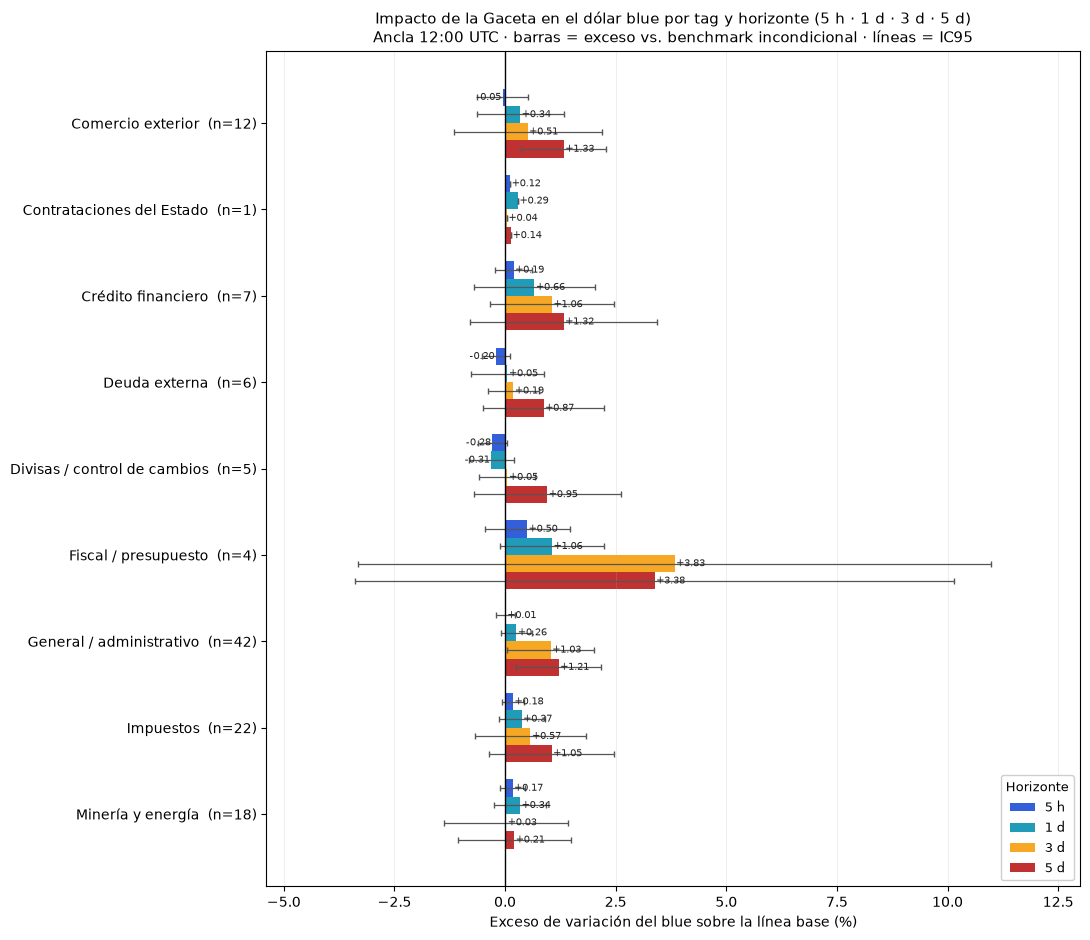

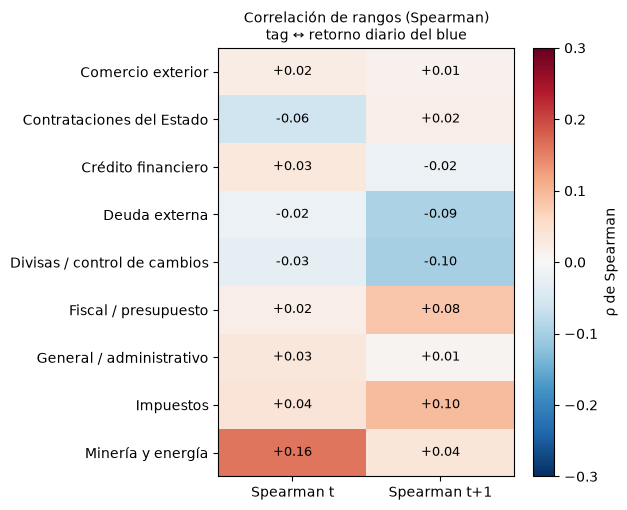

In [22]:
# fig:eventos_gaceta y mapa de correlaciones — generadas aquí
graf = pd.DataFrame({t: {h: d[h]["media"] for h in HOR}
                     for t, d in R["eventos"].items()}).T
err = pd.DataFrame({t: {h: d[h]["ic95"] for h in HOR}
                    for t, d in R["eventos"].items()}).T
n_txt = pd.Series({t: max(d[h]["n"] for h in HOR) for t, d in R["eventos"].items()})

fig = figuras.event_study_tag(graf, err, n_txt,
                              etiqueta_tag=etiqueta_tag, hora_ref=12)
fig.savefig(OUT / "informe_event_study.png", dpi=130, bbox_inches="tight")
plt.show()

corr = pd.DataFrame({
    t: {"spearman_t": v["t"], "spearman_t1": v["t1"]}
    for t, v in R["spearman"].items()}).T
fig = figuras.corr_tag_heatmap(corr, etiqueta_tag=etiqueta_tag)
fig.savefig(OUT / "informe_corr_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()


## 5. Evaluación de negocio

### 5.1 KPIs y matriz de costos

El error de nivel se traduce a Bs operados y la señal direccional a una regla de
costo con falsos positivos y falsos negativos. La matriz se calcula con las
**mismas predicciones walk-forward** de la sección 4, para los dos horizontes.


In [23]:
# 5.1 — señal direccional por horizonte: matriz de confusión (calculada aquí)
# Usa las MISMAS predicciones walk-forward de la sección 4.3 (pred_rl / pred_ar),
# para que la matriz y los RMSE del informe provengan de un único modelo.
from sklearn.metrics import (accuracy_score, confusion_matrix, roc_auc_score,
                             roc_curve)


def a_signo(x, eps=0.0):
    return pd.Series(np.select([x > eps, x < -eps], [1, -1], 0), index=x.index)


filas_dir, scores = [], {}
for h in HORIZONTES:
    for target in ("blue_mid", "brecha_pct"):
        real = series[target].loc[pred_ar[h][target].index]
        prev = series[target].shift(h).loc[real.index]   # último valor del origen
        real_dir = a_signo(real - prev)
        candidatos = {
            "Regresión lineal": pred_rl[h][target],
            f"ARIMA ({h} pasos)": pred_ar[h][target],
        }
        for nombre, serie in candidatos.items():
            score = serie.reindex(real.index) - prev
            pred_dir = a_signo(score)
            ok = (real_dir != 0) & pred_dir.notna() & (pred_dir != 0)
            y_, p_ = real_dir[ok].astype(int), pred_dir[ok].astype(int)
            cm = confusion_matrix(y_, p_, labels=[1, -1])
            filas_dir.append({
                "target": target, "horizonte": h, "modelo": nombre,
                "modo": "cambio_esperado", "n": int(len(y_)),
                "aciertos": int(np.trace(cm)),
                "accuracy": round(float(accuracy_score(y_, p_)), 3),
                "tp": int(cm[0, 0]), "fn": int(cm[0, 1]),
                "fp": int(cm[1, 0]), "tn": int(cm[1, 1]),
            })
            ok2 = (real_dir != 0) & score.notna() & (score != 0)
            y_up = (real_dir[ok2] == 1).astype(int)
            fpr, tpr, _ = roc_curve(y_up, score[ok2])
            scores[(h, target, nombre)] = (
                fpr, tpr, round(float(roc_auc_score(y_up, score[ok2])), 3))

tabla_dir = pd.DataFrame(filas_dir)
display(tabla_dir.set_index(["horizonte", "target", "modelo"]).round(3)
        .rename_axis(["Horizonte", "Nivel", "Modelo"]))

for h in HORIZONTES:
    mc = tabla_dir[(tabla_dir.horizonte == h) & (tabla_dir.target == "blue_mid")
                   & (tabla_dir.modelo == f"ARIMA ({h} pasos)")].iloc[0]
    subas, bajadas = int(mc.tp + mc.fn), int(mc.fp + mc.tn)
    print(f"\n{etiqueta_eje('blue_mid')} · ARIMA {h} pasos → TP {mc.tp} | "
          f"FN {mc.fn} | FP {mc.fp} | TN {mc.tn} | n={mc.n} | "
          f"accuracy {mc.accuracy:.3f}")
    print(f"  horas: {subas} subas y {bajadas} bajadas "
          f"(tasa base {subas / (subas + bajadas):.1%})")
    print(f"  modelo  → {mc.fp}·C_FP + {mc.fn}·C_FN ; trivial → "
          f"{bajadas}·C_FP")
    print(f"  umbral  → aporta si C_FN / C_FP < {mc.tn}/{mc.fn} = "
          f"{mc.tn / mc.fn:.2f}"
          + ("   (imposible en la práctica)" if mc.tn < mc.fn else ""))

# el notebook es la fuente de la matriz: se exporta y el informe la lee
tabla_dir.to_csv(OUT / "informe_direccion.csv", index=False)

mc1 = tabla_dir[(tabla_dir.horizonte == 1) & (tabla_dir.target == "blue_mid")
                & (tabla_dir.modelo == "ARIMA (1 pasos)")].iloc[0]
_prev = (R.get("matriz_costos") or {}).get("1")
if _prev:
    igual = (mc1.tp, mc1.fn, mc1.fp, mc1.tn) == tuple(
        _prev[k] for k in ("tp", "fn", "fp", "tn"))
    print("✔ coincide con metricas_reporte.json" if igual else
          "⚠ el JSON tiene la matriz anterior: volver a correr reporte_modelado.py")


modo    n  aciertos  accuracy  tp   fn  fp  tn
Horizonte Nivel      Modelo                                                                     
1         blue_mid   Regresión lineal  cambio_esperado  140        66     0.471   0   74   0  66
                     ARIMA (1 pasos)   cambio_esperado  140        80     0.571  45   29  31  35
          brecha_pct Regresión lineal  cambio_esperado  141        85     0.603  44   27  29  41
                     ARIMA (1 pasos)   cambio_esperado  141        88     0.624  43   28  25  45
24        blue_mid   Regresión lineal  cambio_esperado  163        53     0.325   0  110   0  53
                     ARIMA (24 pasos)  cambio_esperado  163        79     0.485  56   54  30  23
          brecha_pct Regresión lineal  cambio_esperado  166        62     0.373  21   56  48  41
                     ARIMA (24 pasos)  cambio_esperado  166        94     0.566  43   34  38  51


Blue (medio) [Bs/USD] · ARIMA 1 pasos → TP 45 | FN 29 | FP 31 | TN 35 | n=140 | accuracy 0.571
  horas: 74 subas y 66 bajadas (tasa base 52.9%)
  modelo  → 31·C_FP + 29·C_FN ; trivial → 66·C_FP
  umbral  → aporta si C_FN / C_FP < 35/29 = 1.21

Blue (medio) [Bs/USD] · ARIMA 24 pasos → TP 56 | FN 54 | FP 30 | TN 23 | n=163 | accuracy 0.485
  horas: 110 subas y 53 bajadas (tasa base 67.5%)
  modelo  → 30·C_FP + 54·C_FN ; trivial → 53·C_FP
  umbral  → aporta si C_FN / C_FP < 23/54 = 0.43   (imposible en la práctica)
✔ coincide con metricas_reporte.json


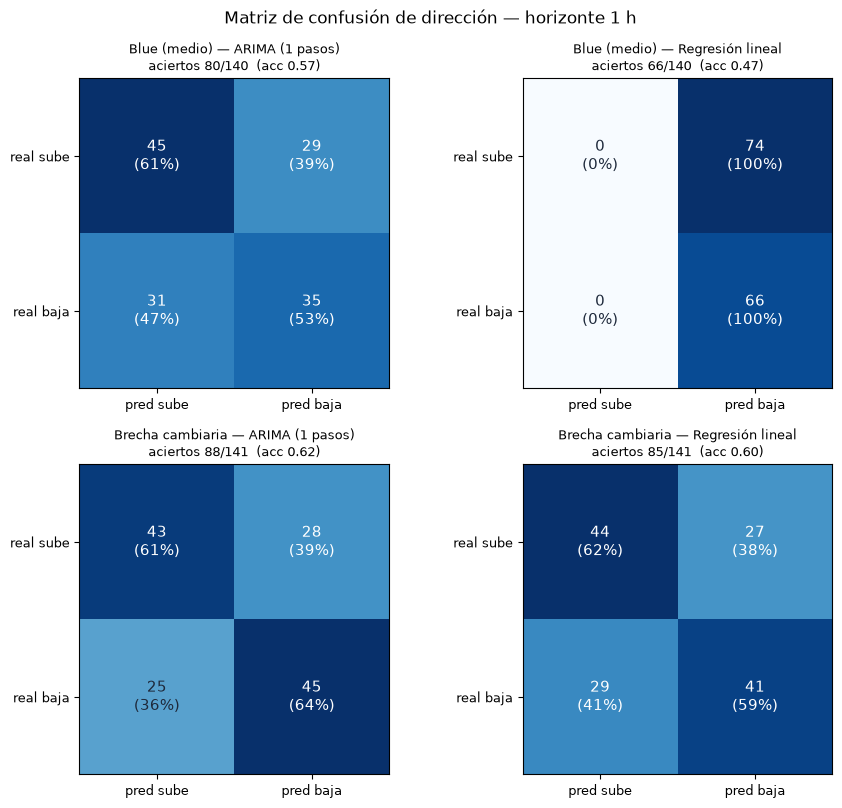

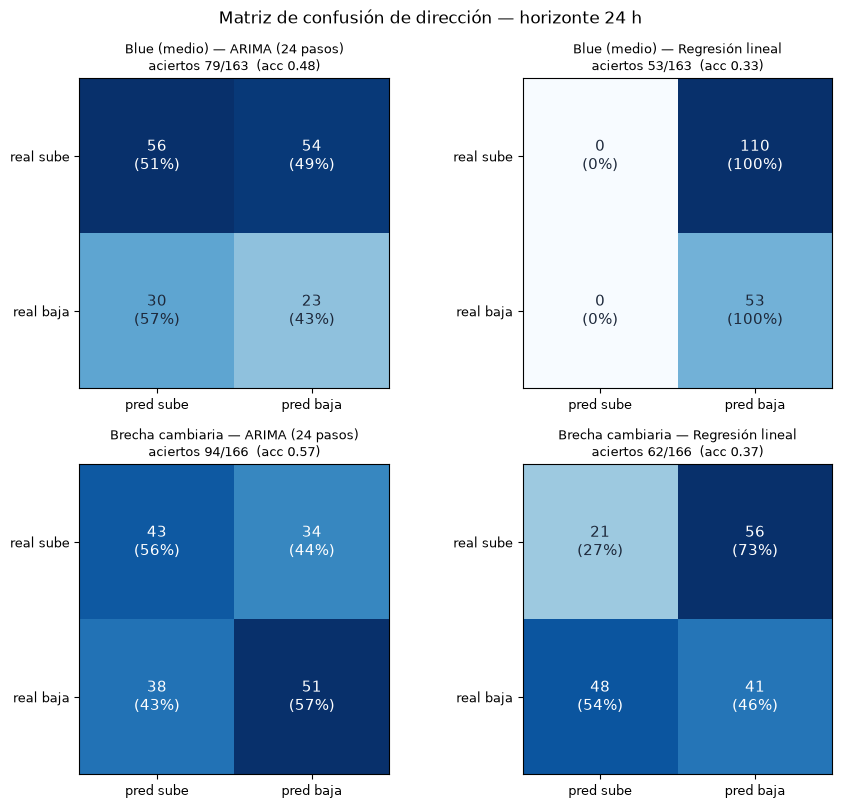

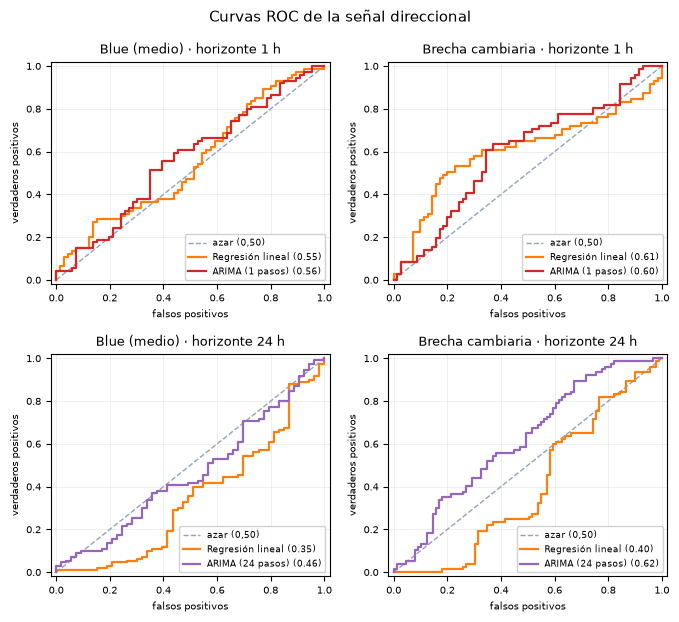

AUC por horizonte, target y modelo
  h= 1 | Blue (medio)           | ARIMA (1 pasos)    | AUC 0.562
  h= 1 | Blue (medio)           | Regresión lineal   | AUC 0.548
  h= 1 | Brecha cambiaria       | ARIMA (1 pasos)    | AUC 0.596
  h= 1 | Brecha cambiaria       | Regresión lineal   | AUC 0.606
  h=24 | Blue (medio)           | ARIMA (24 pasos)   | AUC 0.461
  h=24 | Blue (medio)           | Regresión lineal   | AUC 0.348
  h=24 | Brecha cambiaria       | ARIMA (24 pasos)   | AUC 0.619
  h=24 | Brecha cambiaria       | Regresión lineal   | AUC 0.400


In [24]:
# figuras de la señal: matriz de confusión y curvas ROC, por horizonte
for h in HORIZONTES:
    fig = figuras.confusion_direccion(tabla_dir, etiqueta=etiqueta, horizonte=h)
    fig.savefig(OUT / f"informe_confusion_h{h}.png", dpi=130, bbox_inches="tight")
    plt.show()

fig = figuras.roc_direccion(scores, etiqueta=etiqueta, horizontes=HORIZONTES)
fig.savefig(OUT / "informe_roc.png", dpi=130, bbox_inches="tight")
fig.savefig(FP / "report" / "figures" / "fig_roc.pdf", bbox_inches="tight")
plt.show()

print("AUC por horizonte, target y modelo")
for (h, target, nombre), (_, _, auc) in sorted(scores.items()):
    print(f"  h={h:2d} | {etiqueta(target):22s} | {nombre:18s} | AUC {auc:.3f}")


### 5.2 ROI y costo de adquisición de datos

Ahorro anual por ΔMAE × volumen, y costo de etiquetar la Gaceta con el LLM.


In [25]:
# tab:kpi_mae, tab:kpi_volumen y tab:costo_llm
a = R["por_horizonte"]["1"]["arima"]["blue_mid"]
delta_mae = round(a["mae_naive"] - a["mae"], 4)
print(f"MAE ARIMA a 1 h {a['mae']:.4f} vs naïve {a['mae_naive']:.4f} "
      f"→ ΔMAE = {delta_mae:.4f} Bs/USD")
print(f"a 24 h: MAE {R['por_horizonte']['24']['arima']['blue_mid']['mae']:.4f} vs "
      f"naïve {R['por_horizonte']['24']['arima']['blue_mid']['mae_naive']:.4f}")

display(pd.DataFrame([
    {"Volumen semanal (USD)": f"{v:,}",
     "Ahorro semanal (Bs)": round(delta_mae * v, 0),
     "Ahorro anual (Bs)": round(delta_mae * v * 52, 0)}
    for v in (10_000, 100_000, 1_000_000)]))

ok = gaceta[gaceta.status == "ok"]
costo = float(ok.cost_usd.sum())
print(f"extracción LLM: {len(ok)} normas | costo total ${costo:.4f} | "
      f"${costo / len(ok):.6f}/norma | proyección anual (510 normas) "
      f"${costo / len(ok) * 510:.2f}")


MAE ARIMA a 1 h 0.0050 vs naïve 0.0050 → ΔMAE = 0.0000 Bs/USD
a 24 h: MAE 0.0277 vs naïve 0.0277


,Volumen semanal (USD),Ahorro semanal (Bs),Ahorro anual (Bs)
0,"10,000",0.0,0.0
1,"100,000",0.0,0.0
2,"1,000,000",0.0,0.0


extracción LLM: 169 normas | costo total $0.1173 | $0.000694/norma | proyección anual (510 normas) $0.35


## Hallazgos

- **Objetivo 1 (1 h y 24 h):** el ARIMA **iguala o mejora levemente** al naïve
  en los cuatro casos (RMSE ÷ naïve = 0,96 a 1 h en el nivel; 1,00 y 0,99 en el
  resto). La regresión lineal **pierde siempre** (1,29 en la brecha y 10,6 en el
  nivel a 1 h; 3,2–3,8 a 24 h) y se desborda al extrapolar la brecha a un día.
- **Objetivo 2:** ningún tag de la Gaceta resulta significativo; los canales
  cambiarios muestran el signo esperado pero con n insuficiente.
- **Negocio:** a 1 h la señal evita 35 bajadas y pierde 29 subas, así que
  conviene solo si un falso negativo cuesta menos de 35/29 = **1,21 veces** un
  falso positivo (con costos simétricos ahorra 6 de 66 unidades, 9,1 %). A 24 h
  el umbral cae a 23/54 = **0,43** con accuracy 0,485: la señal direccional es
  un fenómeno de una hora, no de un día.
